# Práctica PCD: Asociación

## EDA

In [1]:
import pandas as pd
import numpy as np
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
import matplotlib.pyplot as plt
import warnings
import time
import tracemalloc
import seaborn as sns



In [2]:
data = pd.read_csv('bread_basket.xls')
print(data.shape)
data.head(10)

(20507, 5)


,Transaction,Item,date_time,period_day,weekday_weekend
0,1,Bread,30-10-2016 09:58,morning,weekend
1,2,Scandinavian,30-10-2016 10:05,morning,weekend
2,2,Scandinavian,30-10-2016 10:05,morning,weekend
3,3,Hot chocolate,30-10-2016 10:07,morning,weekend
4,3,Jam,30-10-2016 10:07,morning,weekend
5,3,Cookies,30-10-2016 10:07,morning,weekend
6,4,Muffin,30-10-2016 10:08,morning,weekend
7,5,Coffee,30-10-2016 10:13,morning,weekend
8,5,Pastry,30-10-2016 10:13,morning,weekend
9,5,Bread,30-10-2016 10:13,morning,weekend


In [3]:
data.isna().sum()

Transaction        0
Item               0
date_time          0
period_day         0
weekday_weekend    0
dtype: int64

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Transaction      20507 non-null  int64
 1   Item             20507 non-null  str  
 2   date_time        20507 non-null  str  
 3   period_day       20507 non-null  str  
 4   weekday_weekend  20507 non-null  str  
dtypes: int64(1), str(4)
memory usage: 801.2 KB


In [5]:
data.nunique()

Transaction        9465
Item                 94
date_time          9182
period_day            4
weekday_weekend       2
dtype: int64

In [6]:
data['period_day'].unique()

<StringArray>
['morning', 'afternoon', 'evening', 'night']
Length: 4, dtype: str

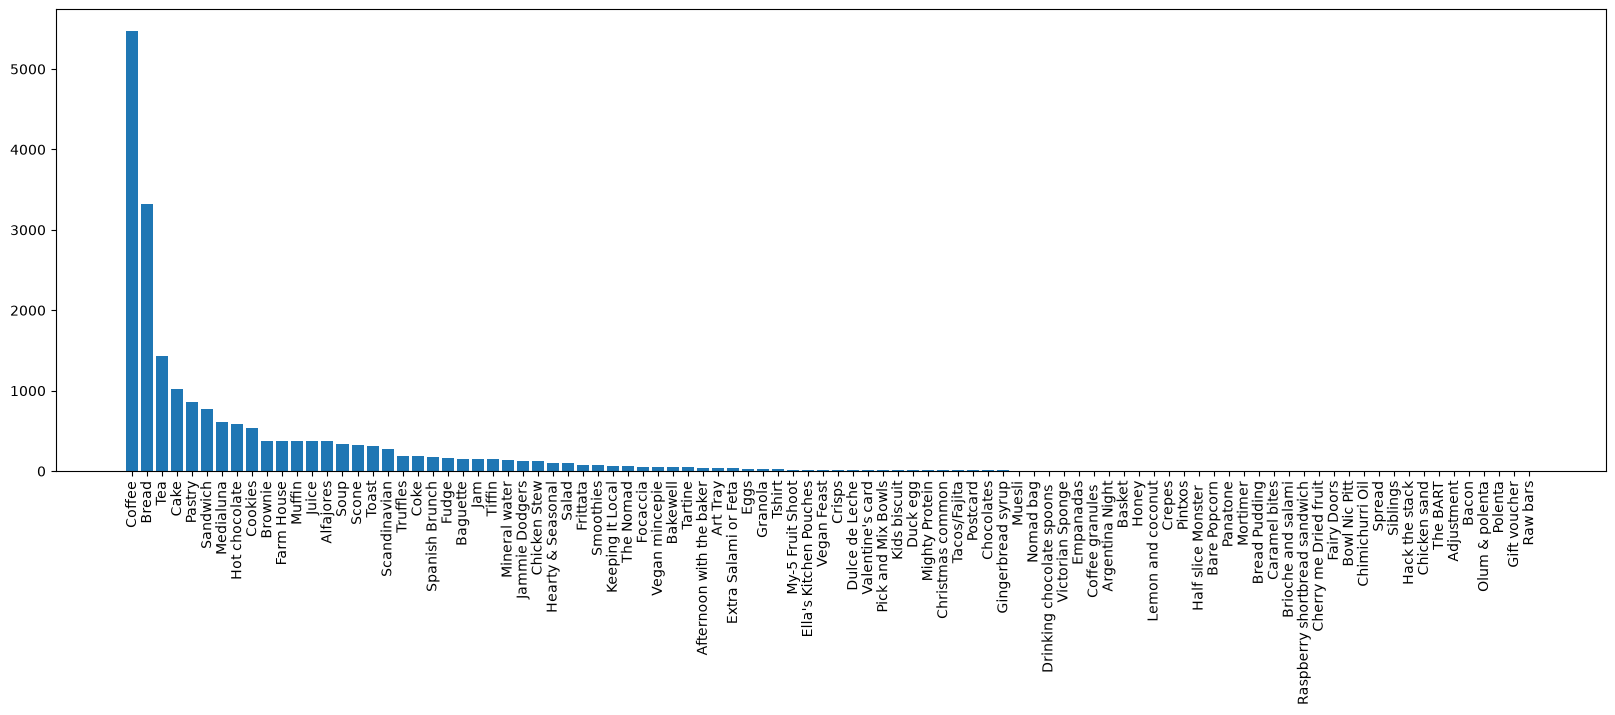

In [7]:
counts = data['Item'].value_counts()
plt.figure(figsize=(20, 6))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=90)
plt.show()



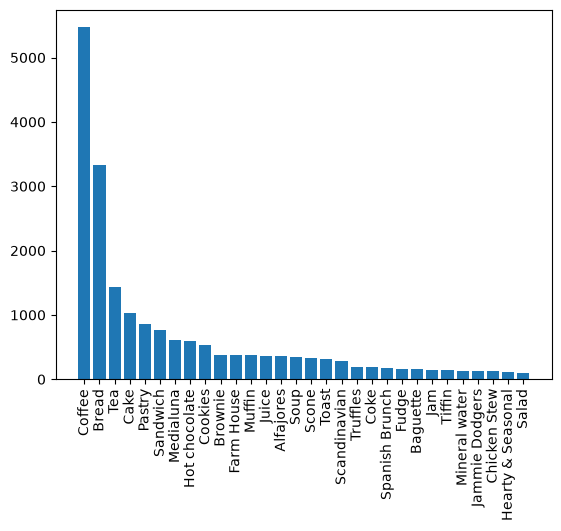

In [8]:
#plt.figure(figsize=(20, 6))
plt.bar(counts.index[:30], counts.values[:30])
plt.xticks(rotation=90)
plt.show()

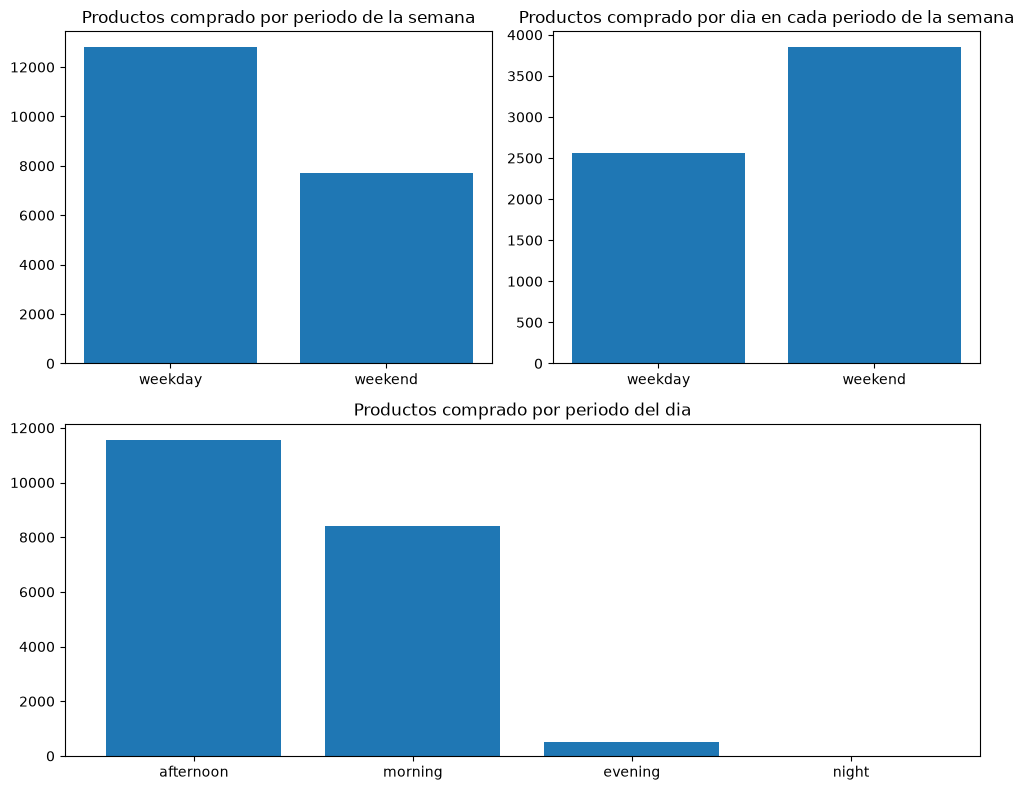

In [9]:
weekend_counts = data['weekday_weekend'].value_counts()
weekend_counts_norm = weekend_counts.astype(float)
weekend_counts_norm['weekend'] = weekend_counts_norm['weekend'] / 2
weekend_counts_norm['weekday'] = weekend_counts_norm['weekday'] / 5

fig, ax = plt.subplot_mosaic(
    [['left', 'right'],
     ['bottom', 'bottom']],
    figsize=(10, 8),
)

ax['left'].bar(weekend_counts.index, weekend_counts.values)
ax['left'].tick_params(axis='x', rotation=0)
ax['left'].set_title('Productos comprado por periodo de la semana')

ax['right'].bar(weekend_counts_norm.index, weekend_counts_norm.values)
ax['right'].tick_params(axis='x', rotation=0)
ax['right'].set_title('Productos comprado por dia en cada periodo de la semana')

period_counts=data['period_day'].value_counts()
ax['bottom'].bar(period_counts.index, period_counts.values)
ax['bottom'].tick_params(axis='x', rotation=0)
ax['bottom'].set_title('Productos comprado por periodo del dia')

plt.tight_layout()
plt.show()

In [10]:
transaction = data.groupby('Transaction').agg(
    Items=('Item', list),
    date_time=('date_time','first'),
    period_day=('period_day','first'),
    weekday_weekend=('weekday_weekend','first')
)

print(transaction.shape)
transaction.head()

(9465, 4)


,Items,date_time,period_day,weekday_weekend
Transaction,,,,
1,[Bread],30-10-2016 09:58,morning,weekend
2,"[Scandinavian, Scandinavian]",30-10-2016 10:05,morning,weekend
3,"[Hot chocolate, Jam, Cookies]",30-10-2016 10:07,morning,weekend
4,[Muffin],30-10-2016 10:08,morning,weekend
5,"[Coffee, Pastry, Bread]",30-10-2016 10:13,morning,weekend


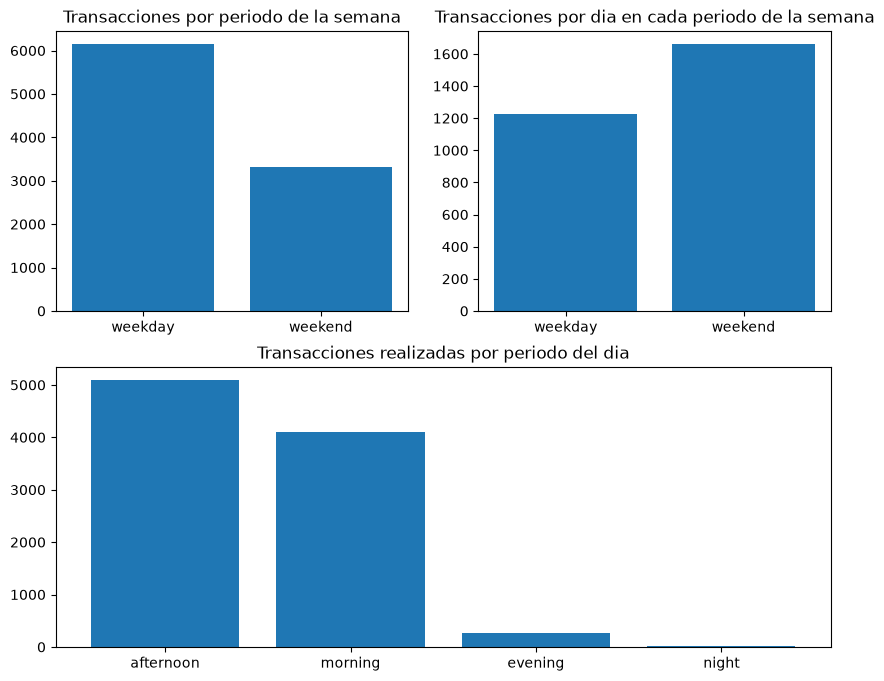

In [11]:
week_transactions = transaction['weekday_weekend'].value_counts()
week_transactions_norm = week_transactions.astype(float)
week_transactions_norm['weekend'] = week_transactions_norm['weekend'] / 2
week_transactions_norm['weekday'] = week_transactions_norm['weekday'] / 5

fig, ax = plt.subplot_mosaic(
    [['left', 'right'],
     ['bottom', 'bottom']],
    figsize=(10, 8),
)

ax['left'].bar(week_transactions.index, week_transactions.values)
ax['left'].tick_params(axis='x')
ax['left'].set_title('Transacciones por periodo de la semana')

ax['right'].bar(week_transactions_norm.index, week_transactions_norm.values)
ax['right'].tick_params(axis='x')
ax['right'].set_title('Transacciones por dia en cada periodo de la semana')


period_counts=transaction['period_day'].value_counts()
ax['bottom'].bar(period_counts.index, period_counts.values)
ax['bottom'].tick_params(axis='x')
ax['bottom'].set_title('Transacciones realizadas por periodo del dia')

plt.show() 

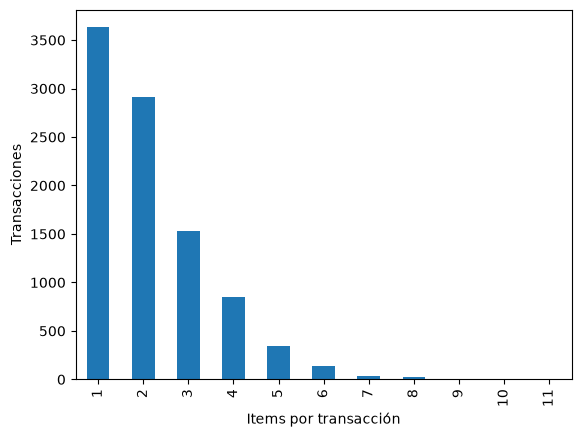

In [12]:

n_items = transaction['Items'].str.len()

n_items.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Items por transacción')
plt.ylabel('Transacciones')
plt.show()

Repeated items within a transaction: 1620
Mean basket size (raw / distinct): 2.17 / 2.00
Single-item transactions: 41.7%


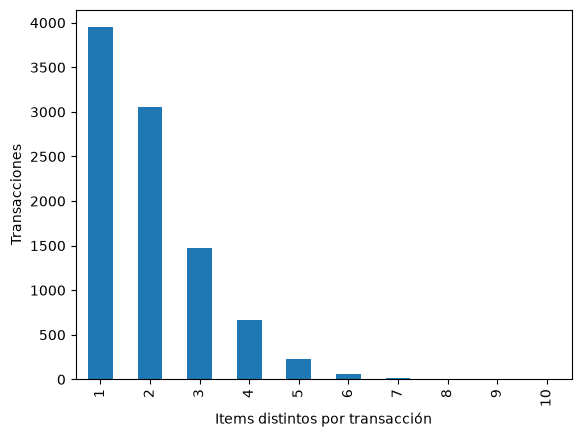

In [13]:
dup_items = data.duplicated(['Transaction', 'Item']).sum()
n_unique_items = transaction['Items'].apply(lambda items: len(set(items)))

print(f'Repeated items within a transaction: {dup_items}')
print(f'Mean basket size (raw / distinct): {n_items.mean():.2f} / {n_unique_items.mean():.2f}')
print(f'Single-item transactions: {(n_unique_items == 1).mean():.1%}')

n_unique_items.value_counts().sort_index().plot(kind='bar')
plt.xlabel('Items distintos por transacción')
plt.ylabel('Transacciones')
plt.show()

Hay 1620 items repetidos dentro de la misma transacción, que inflan el tamaño de cesta (2.17 → 2.00 items distintos de media). El 41.7 % de las transacciones tienen un solo producto: no aportan co-ocurrencias, pero sí cuentan en el denominador del soporte.

Item
Coffee           0.478
Bread            0.327
Tea              0.143
Cake             0.104
Pastry           0.086
Sandwich         0.072
Medialuna        0.062
Hot chocolate    0.058
Cookies          0.054
Brownie          0.040
Name: count, dtype: float64

Items with support >= 1%: 30 / 94
Items with support >= 2%: 19 / 94
Items with support >= 5%: 9 / 94


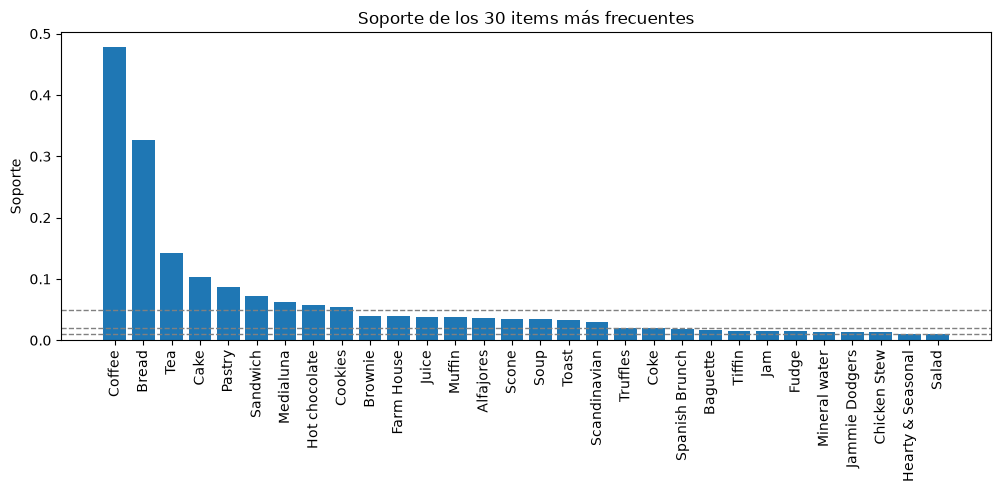

In [14]:

item_support = (
    data.drop_duplicates(['Transaction', 'Item'])['Item'].value_counts()
    / data['Transaction'].nunique()
)
print(item_support.head(10).round(3))
print()
for threshold in [0.01, 0.02, 0.05]:
    print(f'Items with support >= {threshold:.0%}: {(item_support >= threshold).sum()} / {len(item_support)}')

plt.figure(figsize=(12, 4))
plt.bar(item_support.index[:30], item_support.values[:30])
for threshold in [0.01, 0.02, 0.05]:
    plt.axhline(threshold, linestyle='--', linewidth=1, color='gray')
plt.xticks(rotation=90)
plt.ylabel('Soporte')
plt.title('Soporte de los 30 items más frecuentes')
plt.show()

Coffee está en casi la mitad de las transacciones y Bread en un tercio, así que aparecerán como consecuente en muchas reglas con confidence alta pero poco informativas. Solo 30 de 94 items superan el 1 % de soporte.

In [15]:
print(item_support.tail(15).round(4))
print()
print(data['period_day'].value_counts())

Item
Cherry me Dried fruit    0.0003
Fairy Doors              0.0002
Bowl Nic Pitt            0.0002
Chimichurri Oil          0.0002
Spread                   0.0002
Siblings                 0.0002
Hack the stack           0.0002
Chicken sand             0.0001
The BART                 0.0001
Adjustment               0.0001
Bacon                    0.0001
Olum & polenta           0.0001
Polenta                  0.0001
Gift voucher             0.0001
Raw bars                 0.0001
Name: count, dtype: float64

period_day
afternoon    11569
morning       8404
evening        520
night           14
Name: count, dtype: int64


Date range: 2016-10-30 09:58:00 -> 2017-04-09 15:04:00 (159 days)


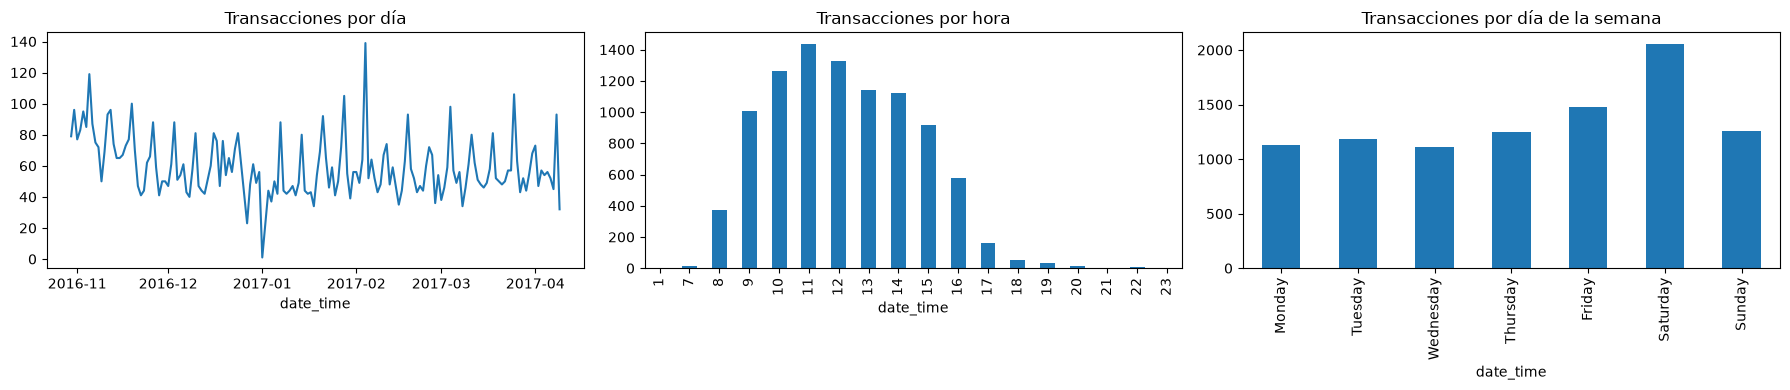

In [16]:
tx_datetime = pd.to_datetime(transaction['date_time'], format='%d-%m-%Y %H:%M')
print(f'Date range: {tx_datetime.min()} -> {tx_datetime.max()} ({tx_datetime.dt.date.nunique()} days)')

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

tx_datetime.dt.date.value_counts().sort_index().plot(ax=ax[0])
ax[0].set_title('Transacciones por día')

tx_datetime.dt.hour.value_counts().sort_index().plot(kind='bar', ax=ax[1])
ax[1].set_title('Transacciones por hora')

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
tx_datetime.dt.day_name().value_counts().reindex(day_order).plot(kind='bar', ax=ax[2])
ax[2].set_title('Transacciones por día de la semana')

plt.tight_layout()
plt.show()

 159 días (oct-2016 - abr-2017), ~60 transacciones al día. La actividad se concentra entre las 9h y las 16h y el sábado es el día más fuerte.

In [17]:
te = TransactionEncoder()
te_ary = te.fit(transaction['Items']).transform(transaction['Items'])
df = pd.DataFrame(te_ary, columns=te.columns_)
df

,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,...,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9460,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9461,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,False
9462,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9463,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


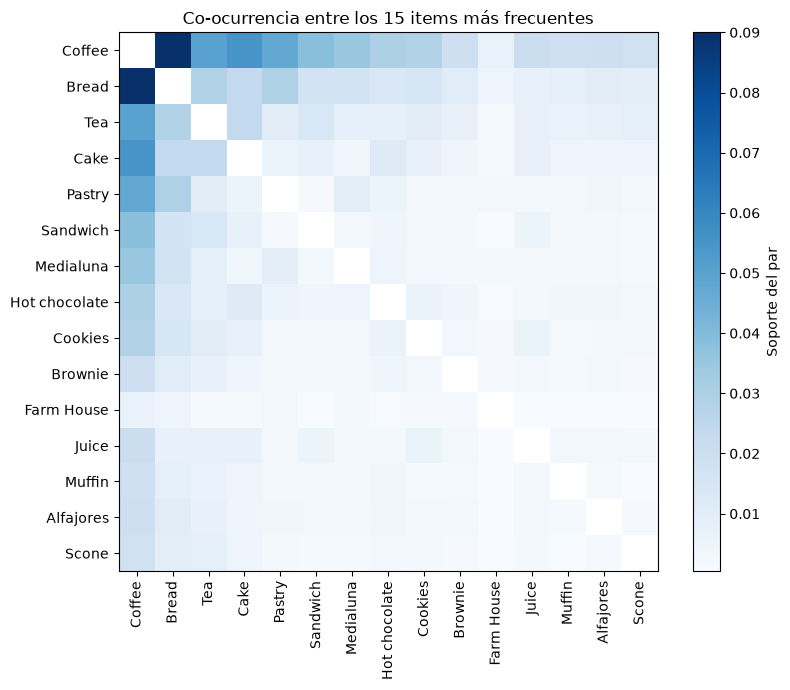

Coffee & Bread -> observed: 0.090 | expected if independent: 0.157 | lift: 0.58


In [18]:

top_items = item_support.index[:15]
top_df = df[top_items].astype(int)
pair_support = (top_df.T @ top_df) / len(df)
pair_support = pair_support.mask(np.eye(len(top_items), dtype=bool))

plt.figure(figsize=(9, 7))
plt.imshow(pair_support, cmap='Blues')
plt.colorbar(label='Soporte del par')
plt.xticks(range(len(top_items)), top_items, rotation=90)
plt.yticks(range(len(top_items)), top_items)
plt.title('Co-ocurrencia entre los 15 items más frecuentes')
plt.show()


observed = pair_support.loc['Coffee', 'Bread']
expected = item_support['Coffee'] * item_support['Bread']
print(f'Coffee & Bread -> observed: {observed:.3f} | expected if independent: {expected:.3f} | lift: {observed / expected:.2f}')

Los pares más frecuentes casi siempre incluyen Coffee (Bread, Cake, Tea, Pastry).Coffee y Bread aparece menos  de lo esperado por azar (lift < 1). 

## Preprocesado

## Modelos 

### 1. Algoritmos y métricas

**Algoritmos comparados:** Apriori y FP-Growth (`mlxtend`) y ECLAT (implementación propia).

**Métricas de calidad** de una regla $A \rightarrow B$:

| Métrica | Fórmula | Lectura |
|---|---|---|
| Soporte | $P(A \cup B)$ | Frecuencia de la regla |
| Confianza | $P(B \mid A)$ | Probabilidad de comprar B si se compra A |
| Lift | $\frac{P(B \mid A)}{P(B)}$ | > 1: asociación positiva; = 1: independencia |
| Conviction | $\frac{1 - P(B)}{1 - P(B \mid A)}$ | > 1: la regla falla menos de lo esperado por azar |
| Leverage | $P(A \cup B) - P(A)P(B)$ | > 0: co-ocurrencia por encima de la independencia (en proporción absoluta) |

**Métricas computacionales:** tiempo de ejecución, memoria pico, nº de reglas generadas y nº de reglas útiles.

In [19]:


def eclat(df, min_support=0.5, use_colnames=True, max_len=None):
    n_transactions = len(df)
    min_count = min_support * n_transactions
    tidsets = [(item, df[item].to_numpy()) for item in df.columns if df[item].sum() >= min_count]
    results = []

    def extend(prefix, prefix_mask, candidates):
        for i, (item, mask) in enumerate(candidates):
            new_mask = mask if prefix_mask is None else prefix_mask & mask
            count = new_mask.sum()
            if count < min_count:
                continue
            itemset = prefix + (item,)
            results.append((count / n_transactions, frozenset(itemset)))
            if max_len is None or len(itemset) < max_len:
                extend(itemset, new_mask, candidates[i + 1:])

    extend((), None, tidsets)
    return pd.DataFrame(results, columns=['support', 'itemsets'])


algorithms = {'Apriori': apriori, 'FP-Growth': fpgrowth, 'ECLAT': eclat}

### 2. Diseño del experimento

- **Factores:** Cruzaremos una serie de factores para conseguir todas las combinaciones posibles (3 algoritmos x 6 supports x 4 confidence threshold = 72 configuraciones. La confianza no se usa en la búsqueda de itemsets frecuentes, se usa en la generación de reglas.
- **Tiempo:** Ejecutamos varias veces la misma configuración (`N_RUNS` veces) para poder cronometrar el tiempo que lleva. 
- **Memoria:** 1 Ejecución extra para mediar la cantidad de memoria usada.
- **Efectividad:** nº de reglas, nº y % de reglas útiles, y media de soporte, confianza, lift, conviction y leverage de las reglas generadas.

In [20]:
SUPPORT_GRID = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
CONFIDENCE_GRID = [0.1, 0.25, 0.5, 0.7]
USEFUL_LIFT = 1.2
N_RUNS = 7
QUALITY_METRICS = ['support', 'confidence', 'lift', 'conviction', 'leverage']


def measure_runtime(algorithm, min_support, n_runs=N_RUNS):
    times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        itemsets = algorithm(df, min_support=min_support, use_colnames=True)
        times.append(time.perf_counter() - start)
    return min(times) * 1000, itemsets


def measure_memory(algorithm, min_support):
    tracemalloc.start()
    algorithm(df, min_support=min_support, use_colnames=True)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak / 1024 ** 2


def build_rules(itemsets, min_confidence, n_runs=N_RUNS):
    times = []
    for _ in range(n_runs):
        start = time.perf_counter()
        rules = association_rules(itemsets, num_itemsets=len(df), metric='confidence', min_threshold=min_confidence)
        times.append(time.perf_counter() - start)
    rules['conviction'] = rules['conviction'].replace(np.inf, np.nan)
    return min(times) * 1000, rules

In [21]:
experiment, all_rules = [], {}
for min_support in SUPPORT_GRID:
    for name, algorithm in algorithms.items():
        mining_ms, itemsets = measure_runtime(algorithm, min_support)
        memory_mb = measure_memory(algorithm, min_support)
        for min_confidence in CONFIDENCE_GRID:
            rules_ms, rules = build_rules(itemsets, min_confidence)
            all_rules[(name, min_support, min_confidence)] = rules
            n_useful = (rules['lift'] >= USEFUL_LIFT).sum()
            experiment.append({
                'algorithm': name,
                'min_support': min_support,
                'min_confidence': min_confidence,
                'mining_ms': mining_ms,
                'rules_ms': rules_ms,
                'total_ms': mining_ms + rules_ms,
                'memory_mb': memory_mb,
                'n_itemsets': len(itemsets),
                'n_rules': len(rules),
                'n_useful_rules': n_useful,
                'useful_ratio': n_useful / len(rules) if len(rules) else np.nan,
                **{f'mean_{metric}': rules[metric].mean() for metric in QUALITY_METRICS},
            })
experiment = pd.DataFrame(experiment)
experiment.round(3)

,algorithm,min_support,min_confidence,mining_ms,rules_ms,total_ms,memory_mb,n_itemsets,n_rules,n_useful_rules,useful_ratio,mean_support,mean_confidence,mean_lift,mean_conviction,mean_leverage
0,Apriori,0.001,0.10,38.638,12.073,50.711,44.851,471,519,279,0.538,0.004,0.293,2.119,1.106,-0.000
1,Apriori,0.001,0.25,38.638,9.910,48.548,44.851,471,226,89,0.394,0.005,0.462,1.937,1.213,-0.000
2,Apriori,0.001,0.50,38.638,9.344,47.981,44.851,471,96,56,0.583,0.005,0.612,1.290,1.486,0.001
3,Apriori,0.001,0.70,38.638,8.483,47.121,44.851,471,14,14,1.000,0.003,0.792,1.655,2.711,0.001
4,FP-Growth,0.001,0.10,46.985,5.556,52.541,0.944,471,519,279,0.538,0.004,0.293,2.119,1.106,-0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,FP-Growth,0.050,0.70,46.830,0.842,47.672,0.069,11,0,0,NaN,NaN,NaN,NaN,NaN,NaN
68,ECLAT,0.050,0.10,6.443,3.447,9.890,0.101,11,4,0,0.000,0.072,0.276,0.838,0.916,-0.031
69,ECLAT,0.050,0.25,6.443,3.405,9.848,0.101,11,2,0,0.000,0.072,0.401,0.838,0.911,-0.031
70,ECLAT,0.050,0.50,6.443,3.742,10.185,0.101,11,1,0,0.000,0.055,0.527,1.102,1.103,0.005


In [22]:
def rule_set(rules):
    return set(zip(rules['antecedents'], rules['consequents'], rules['support'].round(10)))


same_rules = all(
    rule_set(all_rules[(name, s, c)]) == rule_set(all_rules[('Apriori', s, c)])
    for name in algorithms for s in SUPPORT_GRID for c in CONFIDENCE_GRID
)
print(f'Same rules for every algorithm in all {len(SUPPORT_GRID) * len(CONFIDENCE_GRID)} threshold combinations: {same_rules}')

Same rules for every algorithm in all 24 threshold combinations: True


Vemos que los algoritmos están generando exáctamente las mismas reglas para todas la configuraciones. Eso significa que lo que cambia entre modelos es la eficiencia, mientras que la eficacia depende de los umbrales

### 3. Visualización de resultados

#### 3.1 Eficiencia

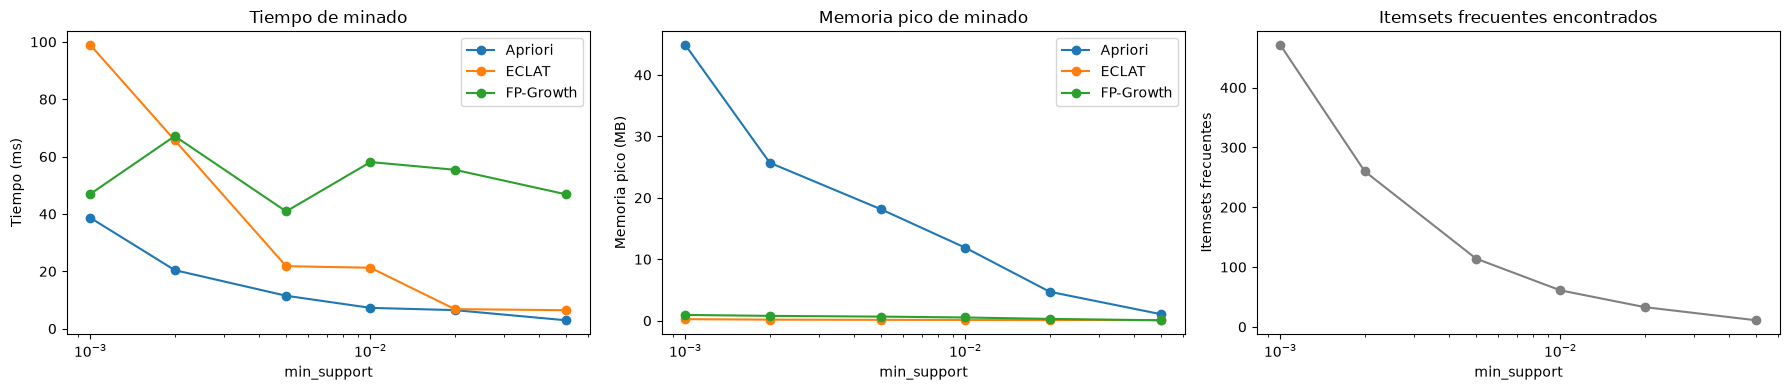

mining_ms                  memory_mb                
algorithm     Apriori  ECLAT FP-Growth   Apriori ECLAT FP-Growth
min_support                                                     
0.001           38.64  98.88     46.99     44.85  0.25      0.94
0.002           20.42  65.72     67.14     25.71  0.17      0.79
0.005           11.48  21.79     40.89     18.12  0.14      0.67
0.010            7.26  21.24     58.10     11.86  0.13      0.53
0.020            6.47   6.82     55.41      4.71  0.11      0.30
0.050            2.92   6.44     46.83      1.05  0.10      0.07

In [23]:
efficiency = experiment.drop_duplicates(['algorithm', 'min_support'])

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for name, group in efficiency.groupby('algorithm'):
    ax[0].plot(group['min_support'], group['mining_ms'], marker='o', label=name)
    ax[1].plot(group['min_support'], group['memory_mb'], marker='o', label=name)
ax[2].plot(efficiency['min_support'].unique(), efficiency.drop_duplicates('min_support')['n_itemsets'], marker='o', color='gray')

for axis, ylabel, title in zip(
    ax,
    ['Tiempo (ms)', 'Memoria pico (MB)', 'Itemsets frecuentes'],
    ['Tiempo de minado', 'Memoria pico de minado', 'Itemsets frecuentes encontrados'],
):
    axis.set_xscale('log')
    axis.set_xlabel('min_support')
    axis.set_ylabel(ylabel)
    axis.set_title(title)
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

efficiency.pivot(index='min_support', columns='algorithm', values=['mining_ms', 'memory_mb']).round(2)

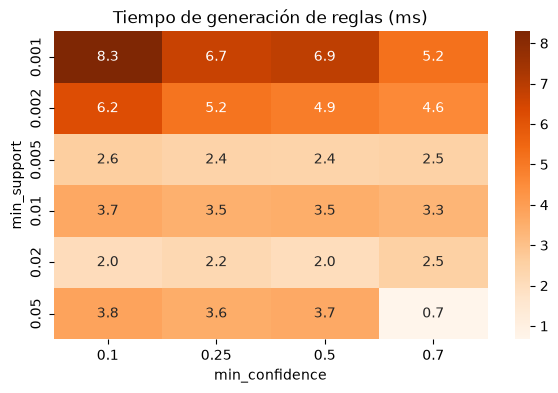

In [24]:
rules_time = experiment.groupby(['min_support', 'min_confidence'])['rules_ms'].median().unstack()

plt.figure(figsize=(7, 4))
sns.heatmap(rules_time, annot=True, fmt='.1f', cmap='Oranges')
plt.title('Tiempo de generación de reglas (ms)')
plt.show()

#### 3.2 Efectividad

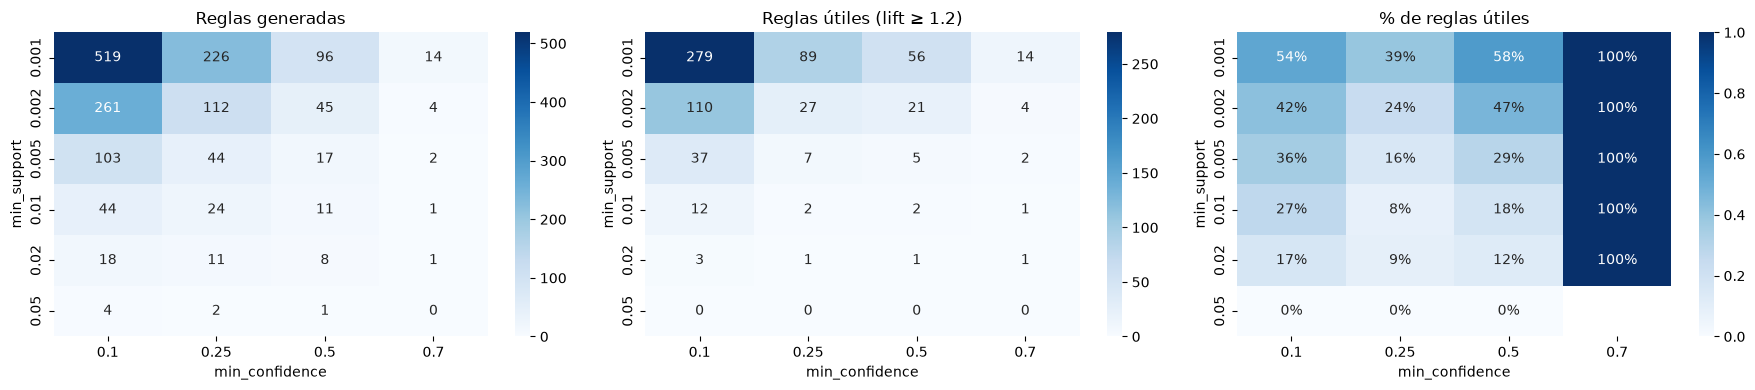

In [25]:
quality = experiment[experiment['algorithm'] == 'Apriori'].set_index(['min_support', 'min_confidence'])

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
for axis, column, title, fmt in zip(
    ax,
    ['n_rules', 'n_useful_rules', 'useful_ratio'],
    ['Reglas generadas', f'Reglas útiles (lift ≥ {USEFUL_LIFT})', '% de reglas útiles'],
    ['d', 'd', '.0%'],
):
    sns.heatmap(quality[column].unstack(), annot=True, fmt=fmt, cmap='Blues', ax=axis)
    axis.set_title(title)
plt.tight_layout()
plt.show()

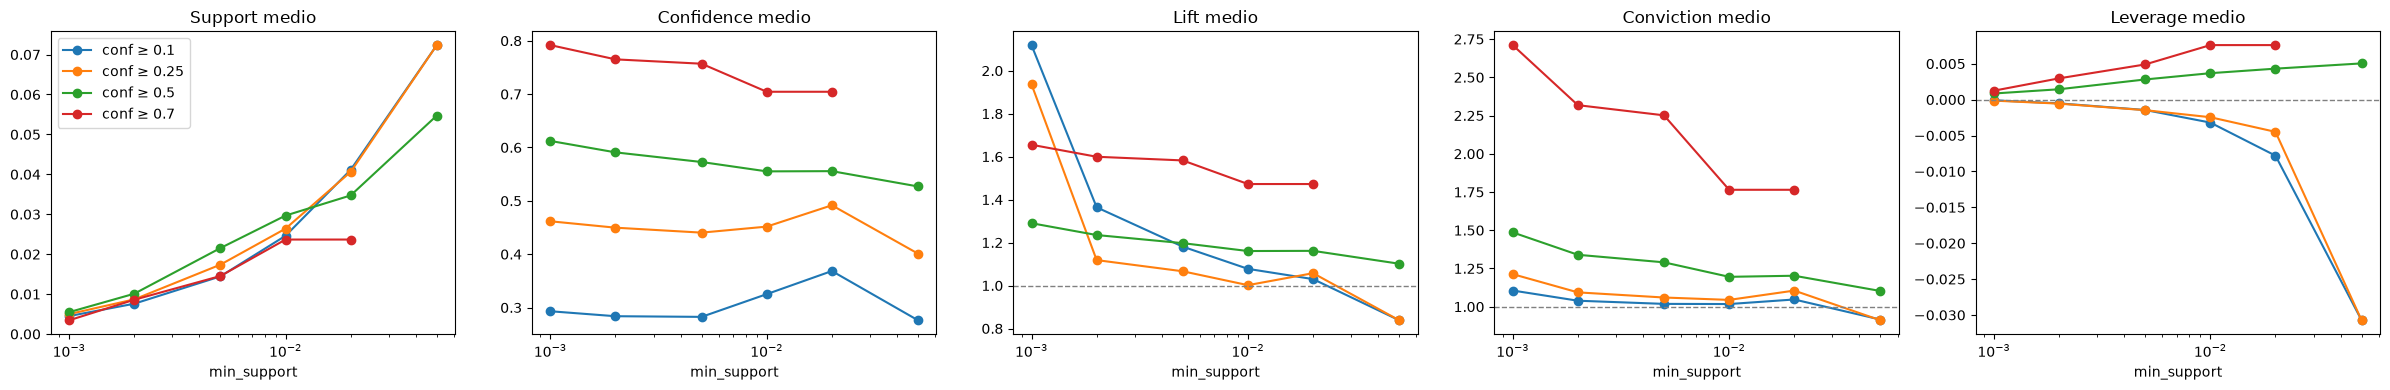

In [26]:
fig, ax = plt.subplots(1, 5, figsize=(24, 4))
for axis, metric in zip(ax, QUALITY_METRICS):
    for min_confidence, group in quality.reset_index().groupby('min_confidence'):
        axis.plot(group['min_support'], group[f'mean_{metric}'], marker='o', label=f'conf ≥ {min_confidence}')
    axis.set_xscale('log')
    axis.set_xlabel('min_support')
    axis.set_title(f'{metric.capitalize()} medio')
ax[2].axhline(1, linestyle='--', color='gray', linewidth=1)
ax[3].axhline(1, linestyle='--', color='gray', linewidth=1)
ax[4].axhline(0, linestyle='--', color='gray', linewidth=1)
ax[0].legend()
plt.tight_layout()
plt.show()

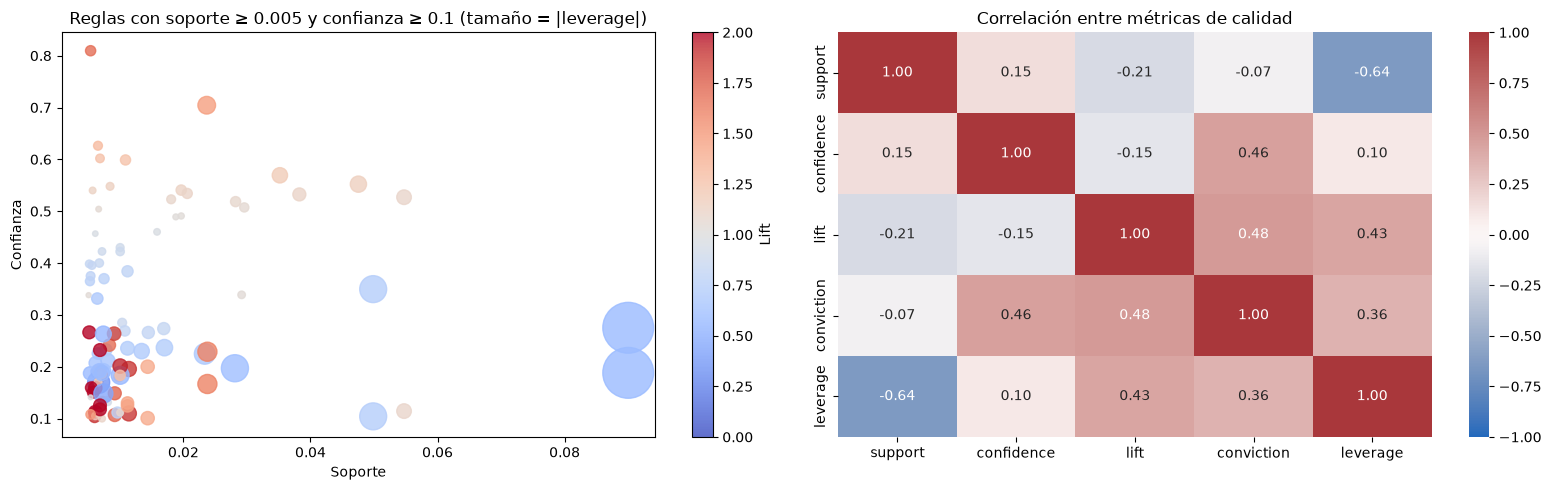

In [27]:
REFERENCE_CONFIG = ('Apriori', 0.005, 0.1)
reference_rules = all_rules[REFERENCE_CONFIG]

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
points = ax[0].scatter(reference_rules['support'], reference_rules['confidence'],
                       c=reference_rules['lift'], s=reference_rules['leverage'].abs() * 20000 + 10,
                       cmap='coolwarm', vmin=0, vmax=2, alpha=0.8)
fig.colorbar(points, ax=ax[0], label='Lift')
ax[0].set_xlabel('Soporte')
ax[0].set_ylabel('Confianza')
ax[0].set_title(f'Reglas con soporte ≥ {REFERENCE_CONFIG[1]} y confianza ≥ {REFERENCE_CONFIG[2]} (tamaño = |leverage|)')

sns.heatmap(reference_rules[QUALITY_METRICS].corr(), annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Correlación entre métricas de calidad')
plt.tight_layout()
plt.show()

In [28]:
useful_rules = reference_rules[reference_rules['lift'] >= USEFUL_LIFT].sort_values('lift', ascending=False).copy()
useful_rules['antecedents'] = useful_rules['antecedents'].apply(lambda s: ', '.join(sorted(s)))
useful_rules['consequents'] = useful_rules['consequents'].apply(lambda s: ', '.join(sorted(s)))
useful_rules[['antecedents', 'consequents'] + QUALITY_METRICS].head(15).round(3)

,antecedents,consequents,support,confidence,lift,conviction,leverage
53,Coke,Sandwich,0.005,0.266,3.707,1.265,0.004
57,Juice,Cookies,0.006,0.159,2.920,1.124,0.004
56,Cookies,Juice,0.006,0.113,2.920,1.083,0.004
94,"Coffee, Hot chocolate",Cake,0.007,0.232,2.235,1.167,0.004
67,Soup,Sandwich,0.005,0.160,2.220,1.104,0.003
93,"Cake, Coffee",Hot chocolate,0.007,0.125,2.152,1.077,0.004
96,Hot chocolate,"Cake, Coffee",0.007,0.118,2.152,1.071,0.004
60,Juice,Sandwich,0.006,0.151,2.097,1.093,0.003
97,"Coffee, Tea",Cake,0.010,0.201,1.938,1.122,0.005
55,Hot chocolate,Cookies,0.006,0.103,1.898,1.054,0.003


### 4. Análisis en profundidad de las reglas

#### 4.1 Elección del modelo
Los tres algoritmos generan exactamente las mismas reglas (sección 3), así que el análisis de las reglas es idéntico con cualquiera de ellos. El criterio de elección es, por tanto, la eficiencia con el umbral de trabajo.

**Umbral de trabajo: `min_support = 0.005`.** Con soporte 5 % no queda ninguna regla útil, y con 0.1–0.2 % salen cientos de reglas, que pueden apoyarse en apenas 10–19 cestas. Con 0.5 % cada regla se apoya en al menos ~47 cestas, lo que reduce el riesgo de asociaciones fruto del azar (Webb, 2007).

No se filtra por confianza: como se vio en la sección 3, una confianza alta no implica que la regla sea interesante, así que la selección se hace por lift y por significación estadística.

In [29]:
ANALYSIS_SUPPORT = 0.005

candidates = (
    experiment[experiment['min_support'] == ANALYSIS_SUPPORT]
    .drop_duplicates('algorithm')
    .set_index('algorithm')[['mining_ms', 'memory_mb', 'n_itemsets']]
)
best_algorithm = candidates['mining_ms'].idxmin()
print(f'Best algorithm at min_support = {ANALYSIS_SUPPORT}: {best_algorithm}')
candidates.round(2)

Best algorithm at min_support = 0.005: Apriori


,mining_ms,memory_mb,n_itemsets
algorithm,,,
Apriori,11.48,18.12,114
FP-Growth,40.89,0.67,114
ECLAT,21.79,0.14,114


#### 4.2 Reglas, métricas y significación estadística
Además de las métricas del benchmark, se añaden:
- **Cestas observadas frente a esperadas** (`n_baskets`, `expected_baskets`): cuántas cestas contienen la regla y cuántas cabría esperar si los productos fueran independientes. Es el lift expresado en cestas.
- **Confianza inversa** (`reverse_confidence`): la confianza de B → A. El lift es simétrico, pero la utilidad práctica de una regla depende de su dirección.
- **Kulczynski e Imbalance Ratio** (Wu, Chen y Han, 2010). Kulczynski es la media de las dos confianzas y no depende de las cestas que no contienen ninguno de los dos productos (es *null-invariant*). El Imbalance Ratio mide lo desequilibrada que es la frecuencia de los dos lados. Los autores recomiendan leerlas juntas cuando un lado es mucho más frecuente que el otro, como ocurre aquí con Coffee.
- **Significación estadística:** test exacto de Fisher unilateral sobre la tabla 2×2 de cada regla (asociación positiva y negativa por separado). Al evaluar cientos de reglas a la vez, una parte saldría significativa por puro azar (Webb, 2007), así que se corrigen los p-valores de dos formas: Benjamini-Hochberg (controla la proporción de falsos descubrimientos) y Bonferroni (más estricta, controla la probabilidad de cometer un solo error).

In [30]:
from scipy.stats import fisher_exact, false_discovery_control


def basket_mask(matrix, itemset):
    return matrix[list(itemset)].all(axis=1).to_numpy()


def contingency_table(matrix, antecedent, consequent):
    a, c = basket_mask(matrix, antecedent), basket_mask(matrix, consequent)
    return [[(a & c).sum(), (a & ~c).sum()], [(~a & c).sum(), (~a & ~c).sum()]]


def pair_lift(matrix, antecedent, consequent):
    a, c = basket_mask(matrix, antecedent), basket_mask(matrix, consequent)
    return (a & c).mean() / (a.mean() * c.mean()) if a.any() and c.any() else np.nan


def join_items(itemset):
    return ', '.join(sorted(itemset))


def is_single_pair(rules):
    return (rules['antecedents'].apply(len) == 1) & (rules['consequents'].apply(len) == 1)


def collapse_directions(rules):
    pairs = [frozenset([a, c]) for a, c in zip(rules['antecedents'], rules['consequents'])]
    return (rules.assign(pair=pairs)
            .sort_values('confidence', ascending=False)
            .drop_duplicates('pair')
            .sort_values('lift', ascending=False))


itemsets = algorithms[best_algorithm](df, min_support=ANALYSIS_SUPPORT, use_colnames=True)
rules = association_rules(itemsets, num_itemsets=len(df), metric='confidence', min_threshold=0)
rules['antecedent'] = rules['antecedents'].apply(join_items)
rules['consequent'] = rules['consequents'].apply(join_items)
rules['n_baskets'] = (rules['support'] * len(df)).round().astype(int)
rules['expected_baskets'] = (rules['antecedent support'] * rules['consequent support'] * len(df)).round().astype(int)
rules['reverse_confidence'] = rules['support'] / rules['consequent support']
rules['imbalance_ratio'] = (rules['antecedent support'] - rules['consequent support']).abs() / (
    rules['antecedent support'] + rules['consequent support'] - rules['support'])

tables = [contingency_table(df, a, c) for a, c in zip(rules['antecedents'], rules['consequents'])]
rules['p_positive'] = [fisher_exact(t, alternative='greater').pvalue for t in tables]
rules['p_negative'] = [fisher_exact(t, alternative='less').pvalue for t in tables]
rules['q_positive'] = false_discovery_control(rules['p_positive'], method='bh')
rules['q_negative'] = false_discovery_control(rules['p_negative'], method='bh')
rules['bonferroni_positive'] = (rules['p_positive'] * len(rules)).clip(upper=1)

positive = rules[(rules['lift'] >= USEFUL_LIFT) & (rules['q_positive'] < 0.05)]
negative = rules[(rules['lift'] < 1) & (rules['q_negative'] < 0.05)]

print(f'Rules generated: {len(rules)}')
print(f"Rules with lift >= {USEFUL_LIFT}: {(rules['lift'] >= USEFUL_LIFT).sum()}")
print(f'  significant (Benjamini-Hochberg, q < 0.05): {len(positive)}')
print(f"  significant (Bonferroni, p < 0.05): {((rules['lift'] >= USEFUL_LIFT) & (rules['bonferroni_positive'] < 0.05)).sum()}")
print(f"Rules with lift < 1: {(rules['lift'] < 1).sum()}")
print(f'  significant negative associations (q < 0.05): {len(negative)}')

Rules generated: 194
Rules with lift >= 1.2: 58
  significant (Benjamini-Hochberg, q < 0.05): 56
  significant (Bonferroni, p < 0.05): 36
Rules with lift < 1: 90
  significant negative associations (q < 0.05): 64


- De las 58 reglas con lift ≥ 1.2, **56 son significativas con Benjamini-Hochberg**, pero solo **36 con Bonferroni**. Las que no superan Bonferroni son las más débiles (lift 1.25–1.50, apoyadas en 51–103 cestas): son las que más riesgo tienen de ser azar.
- Hay además **64 reglas con asociación negativa significativa**: combinaciones que aparecen *menos* de lo esperado. Se analizan en la sección 4.5.
- A → B y B → A comparten la misma tabla 2×2 y, por tanto, el mismo lift y el mismo p-valor. Las 56 reglas positivas significativas son en realidad **28 asociaciones**, cada una en sus dos direcciones. En las tablas siguientes se muestra una vez cada asociación, en la dirección con más confianza.

#### 4.3 Asociaciones positivas: qué productos se compran juntos

In [31]:
RULE_COLUMNS = ['antecedent', 'consequent', 'n_baskets', 'expected_baskets', 'confidence', 'reverse_confidence',
                'lift', 'conviction', 'leverage', 'kulczynski', 'imbalance_ratio', 'q_positive']

positive_pairs = collapse_directions(positive)
print(f'Distinct associations (both directions collapsed): {len(positive_pairs)}')
positive_pairs[RULE_COLUMNS].round(3)

Distinct associations (both directions collapsed): 28


,antecedent,consequent,n_baskets,expected_baskets,confidence,reverse_confidence,lift,conviction,leverage,kulczynski,imbalance_ratio,q_positive
100,Coke,Sandwich,49,13,0.266,0.072,3.707,1.265,0.004,0.169,0.609,0.000
105,Juice,Cookies,58,20,0.159,0.113,2.920,1.124,0.004,0.136,0.182,0.000
177,"Coffee, Hot chocolate",Cake,65,29,0.232,0.066,2.235,1.167,0.004,0.149,0.587,0.000
125,Soup,Sandwich,52,23,0.160,0.076,2.220,1.104,0.003,0.118,0.371,0.000
176,"Cake, Coffee",Hot chocolate,65,30,0.125,0.118,2.152,1.077,0.004,0.122,0.034,0.000
112,Juice,Sandwich,55,26,0.151,0.081,2.097,1.093,0.003,0.116,0.318,0.000
182,"Coffee, Tea",Cake,95,49,0.201,0.097,1.938,1.122,0.005,0.149,0.376,0.000
102,Cookies,Hot chocolate,57,30,0.111,0.103,1.898,1.059,0.003,0.107,0.037,0.000
47,Hot chocolate,Cake,108,57,0.196,0.110,1.884,1.114,0.005,0.153,0.302,0.000
131,Soup,Tea,86,46,0.264,0.064,1.850,1.165,0.004,0.164,0.644,0.000


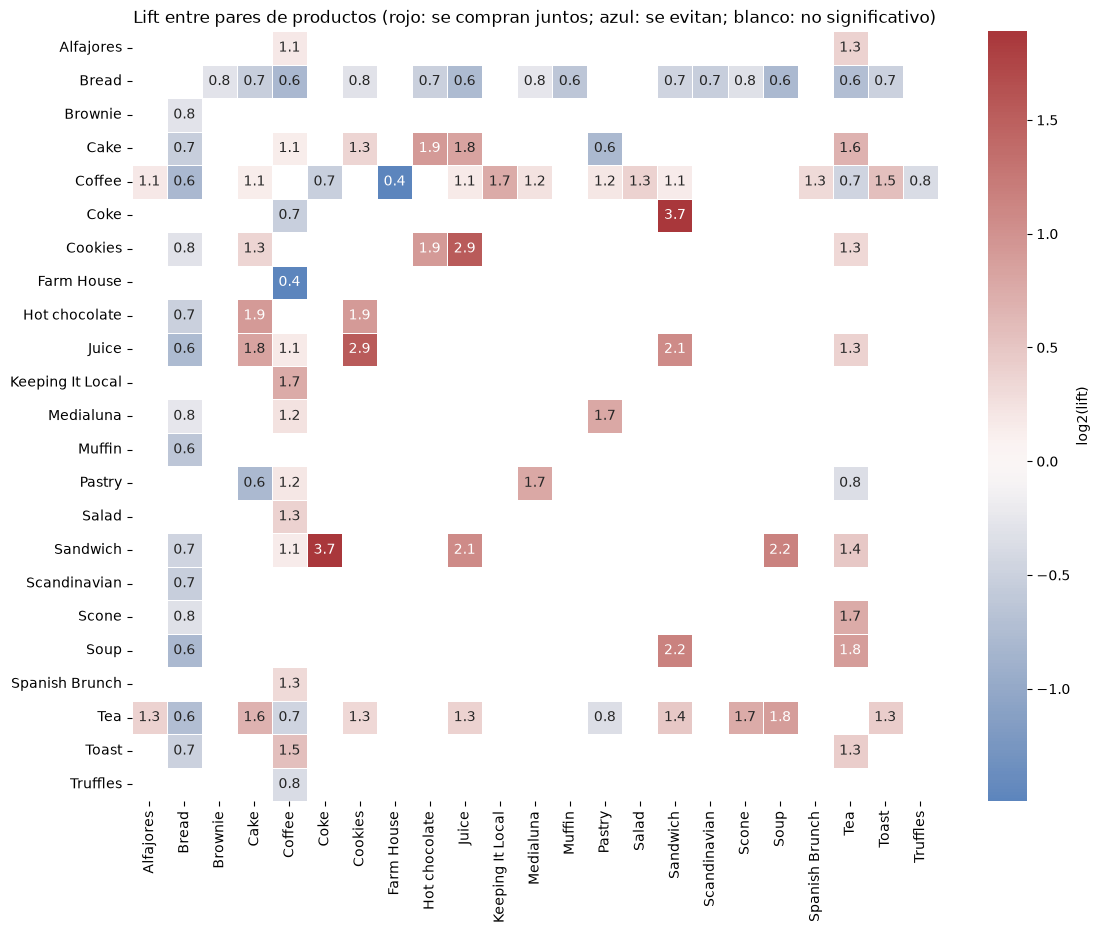

In [32]:
significant_pairs = rules[is_single_pair(rules) & ((rules['q_positive'] < 0.05) | (rules['q_negative'] < 0.05))]
pair_items = sorted(set(significant_pairs['antecedent']))
lift_matrix = significant_pairs.pivot(index='antecedent', columns='consequent', values='lift').reindex(index=pair_items, columns=pair_items)

plt.figure(figsize=(13, 10))
sns.heatmap(np.log2(lift_matrix), cmap='vlag', center=0, annot=lift_matrix.round(1), fmt='',
            cbar_kws={'label': 'log2(lift)'}, linewidths=0.5, linecolor='white')
plt.title('Lift entre pares de productos (rojo: se compran juntos; azul: se evitan; blanco: no significativo)')
plt.xlabel('')
plt.ylabel('')
plt.show()

Las 28 asociaciones forman tres grupos claros, que coinciden con lo que la literatura de marketing llama **misiones de compra**: grupos de productos complementarios que se compran juntos para cubrir una necesidad concreta, como «desayuno» o «comida de mediodía» (Sarantopoulos et al., 2016).

1. **Bebida + dulce.** Hot chocolate + Cake (108 cestas frente a 57 esperadas, lift 1.88; con Coffee, 2.24), Tea + Cake (225 frente a 140, lift 1.60), Juice + Cookies (lift 2.92), Cookies + Hot chocolate (1.90), Juice + Cake (1.77) y Scone + Tea (1.69). Es una complementariedad de consumo: un producto acompaña al otro en el mismo momento (Manchanda et al., 1999).
2. **Comida de mediodía.** Sandwich + Coke (lift 3.71, la asociación más fuerte del dataset), Sandwich + Soup (2.22), Sandwich + Juice (2.10), Sandwich + Tea (1.40) y Soup + Tea (1.85). Es la estructura de un «menú»: plato principal + bebida o acompañamiento.
3. **Desayuno con café.** Toast → Coffee (224 cestas, confianza 0.70), Medialuna + Pastry (1.73), Pastry → Bread + Coffee (1.45) y Spanish Brunch → Coffee.

**La dirección importa aunque el lift sea simétrico.** Toast → Coffee tiene confianza 0.70, pero Coffee → Toast solo 0.05: casi todos los que piden tostada toman café, pero muy pocos de los que toman café piden tostada. La conviction lo refleja porque, a diferencia del lift, depende de la dirección (1.76 frente a 1.02; Brin, Motwani, Ullman y Tsur, 1997). El Imbalance Ratio de 0.91 confirma que es un par muy desequilibrado, y por eso Wu, Chen y Han (2010) recomiendan leerlo junto a Kulczynski (0.38: asociación moderada). En la práctica, la regla útil es la que tiene como antecedente el producto menos frecuente.

**Coffee actúa como producto «comodín».** Aparece como consecuente con confianza muy alta (Keeping It Local → Coffee 0.81, Salad → Coffee 0.63, Spanish Brunch → Coffee 0.60) pero con lift bajo (1.25–1.7). Es el sesgo de la confianza que describen Brin, Motwani y Silverstein (1997) y Tan et al. (2004): Coffee está en el 48 % de las cestas, así que cualquier regla que lo tenga como consecuente parte de una confianza alta.

En el mapa de calor destaca también la **fila de Bread, casi entera en azul**: se compra menos de lo esperado con casi todo. Se analiza en la sección 4.5.

#### 4.4 ¿Complementariedad o coincidencia? El efecto de la franja horaria
Manchanda, Ansari y Gupta (1999) distinguen dos razones por las que dos productos aparecen juntos en la cesta:
- **Complementariedad:** comprar uno aumenta la probabilidad de comprar el otro porque se consumen juntos.
- **Coincidencia:** ambos dependen de un factor común (por ejemplo, el momento de la compra), aunque no tengan relación directa entre sí.

La distinción importa porque solo la complementariedad se puede aprovechar con acciones comerciales. La hora del día es un candidato claro a factor común: si dos productos se venden sobre todo a mediodía, al juntar todas las franjas su lift sale > 1 aunque dentro del mediodía sean independientes. Es un caso de **paradoja de Simpson**, cuya detección se ha propuesto como forma de descubrir patrones sorprendentes (Fabris y Freitas, 2000).

Para separar ambos efectos se recalcula el lift de las asociaciones más fuertes **dentro de cada franja horaria**. Solo mañana y tarde, porque `evening` y `night` tienen muy pocas cestas.

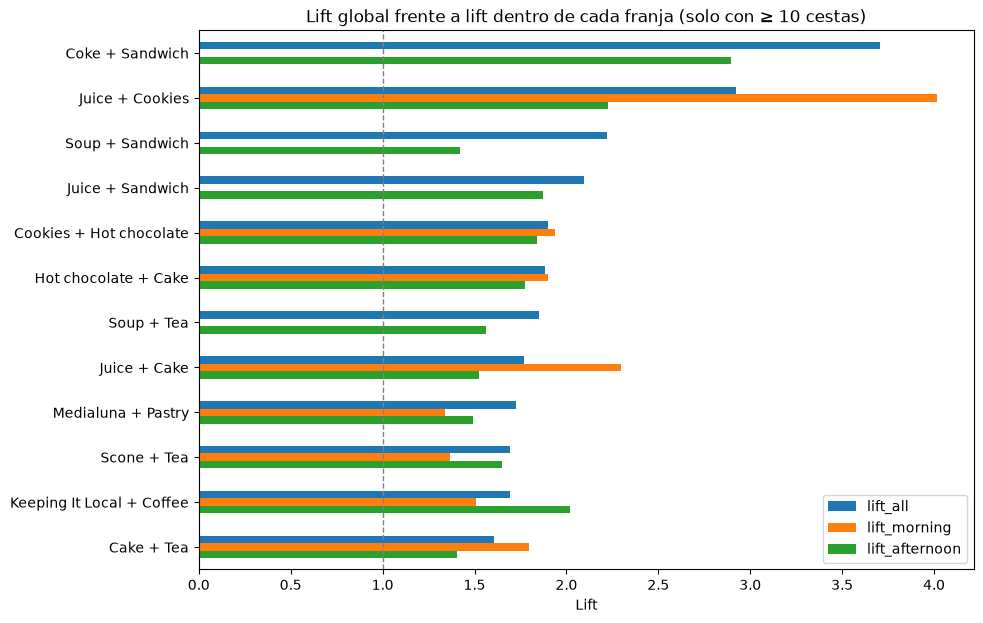

,antecedent,consequent,lift_all,lift_morning,n_morning,lift_afternoon,n_afternoon
100,Coke,Sandwich,3.71,NaN,2,2.90,47
105,Juice,Cookies,2.92,4.02,25,2.23,29
125,Soup,Sandwich,2.22,NaN,1,1.42,51
112,Juice,Sandwich,2.10,NaN,7,1.87,48
102,Cookies,Hot chocolate,1.90,1.94,20,1.84,34
47,Hot chocolate,Cake,1.88,1.90,26,1.78,76
131,Soup,Tea,1.85,NaN,4,1.56,82
49,Juice,Cake,1.77,2.30,19,1.52,46
117,Medialuna,Pastry,1.73,1.34,71,1.49,13
128,Scone,Tea,1.69,1.37,16,1.65,60


In [33]:
PERIODS = ['morning', 'afternoon']
MIN_CONTEXT_BASKETS = 10
period_of_basket = transaction['period_day'].to_numpy()

top_pairs = collapse_directions(positive[is_single_pair(positive)]).head(12)
context = top_pairs[['antecedent', 'consequent', 'lift']].rename(columns={'lift': 'lift_all'})
for period in PERIODS:
    subset = df[period_of_basket == period]
    n_baskets = [int((basket_mask(subset, a) & basket_mask(subset, c)).sum())
                 for a, c in zip(top_pairs['antecedents'], top_pairs['consequents'])]
    lifts = [pair_lift(subset, a, c) for a, c in zip(top_pairs['antecedents'], top_pairs['consequents'])]
    context[f'lift_{period}'] = [lift if n >= MIN_CONTEXT_BASKETS else np.nan for lift, n in zip(lifts, n_baskets)]
    context[f'n_{period}'] = n_baskets

labels = context['antecedent'] + ' + ' + context['consequent']
context[['lift_all', 'lift_morning', 'lift_afternoon']].set_axis(labels).plot(kind='barh', figsize=(10, 7))
plt.axvline(1, linestyle='--', color='gray', linewidth=1)
plt.xlabel('Lift')
plt.title(f'Lift global frente a lift dentro de cada franja (solo con ≥ {MIN_CONTEXT_BASKETS} cestas)')
plt.gca().invert_yaxis()
plt.show()

context.round(2)

In [34]:
context_items = sorted(set(top_pairs['antecedent']) | set(top_pairs['consequent']))
df[context_items].groupby(period_of_basket).mean().loc[PERIODS].T.round(3)

,morning,afternoon
Cake,0.063,0.137
Coffee,0.515,0.460
Coke,0.008,0.028
Cookies,0.048,0.059
Hot chocolate,0.053,0.062
Juice,0.032,0.043
Keeping It Local,0.012,0.003
Medialuna,0.093,0.037
Pastry,0.139,0.046
Sandwich,0.021,0.116


- **Soup + Sandwich es en buena parte coincidencia.** Su lift baja de 2.22 a **1.42 dentro de la tarde**, donde están 51 de sus 52 cestas. Ambos son productos de mediodía (Soup: 0.4 % de las cestas de mañana frente a 6.1 % de las de tarde; Sandwich: 2.1 % frente a 11.6 %), y eso infla el lift global.
- **Coke + Sandwich es complementariedad real.** Dentro de la tarde mantiene un lift de **2.90**. Lo mismo ocurre con Juice + Sandwich (1.87), Hot chocolate + Cake (1.90 por la mañana y 1.78 por la tarde) y Cookies + Hot chocolate (1.94 y 1.84), que se mantienen en ambas franjas.
- **Medialuna + Pastry es en parte coincidencia** de la franja de mañana (Pastry: 13.9 % de las cestas de mañana frente a 4.6 % de las de tarde). Por la mañana, donde se concentran sus cestas, el lift baja de 1.73 a 1.34.
- **Juice + Cookies es más fuerte por la mañana** (4.02 frente a 2.23).

*Implicación:* un lift global alto no basta para concluir que dos productos son complementarios. Hay que controlar el contexto de la compra, y las reglas segmentadas por franja horaria son más fiables y más accionables.

#### 4.5 Asociaciones negativas: sustitutos y misiones de compra distintas

In [35]:
negative_pairs = collapse_directions(negative).sort_values('lift')
print(f'Distinct negative associations: {len(negative_pairs)}')
negative_pairs[['antecedent', 'consequent', 'n_baskets', 'expected_baskets', 'confidence', 'lift', 'leverage', 'q_negative']].head(15).round(3)

Distinct negative associations: 32


,antecedent,consequent,n_baskets,expected_baskets,confidence,lift,leverage,q_negative
63,Farm House,Coffee,63,177,0.170,0.355,-0.012,0.0
170,"Coffee, Tea",Bread,70,154,0.148,0.453,-0.009,0.0
172,"Bread, Tea",Coffee,70,127,0.263,0.550,-0.006,0.0
135,"Cake, Coffee",Bread,95,169,0.183,0.560,-0.008,0.0
140,"Coffee, Cookies",Bread,50,87,0.187,0.572,-0.004,0.0
164,"Coffee, Sandwich",Bread,68,118,0.188,0.574,-0.005,0.0
11,Bread,Coffee,852,1482,0.275,0.575,-0.067,0.0
171,"Bread, Coffee",Tea,70,122,0.082,0.576,-0.005,0.0
50,Pastry,Cake,49,85,0.060,0.579,-0.004,0.0
33,Soup,Bread,62,107,0.190,0.581,-0.005,0.0


Las reglas negativas indican qué productos se compran juntos *menos* de lo esperado. Savasere, Omiecinski y Navathe (1998) y Wu, Zhang y Zhang (2004) defienden que estas relaciones de ausencia son tan informativas como las positivas. Aquí aparecen dos fenómenos distintos:

**1. Dos misiones de compra separadas: comprar pan frente a tomar algo en la cafetería.** Casi todas las asociaciones negativas involucran a Bread:
- Bread + Coffee aparece en 852 cestas frente a 1482 esperadas (lift 0.58). Es el par más frecuente del dataset y, sin embargo, está asociado *negativamente*.
- Farm House (un tipo de pan) + Coffee: 63 cestas frente a 177 esperadas (lift 0.36).
- Bread también se evita con Tea, Soup, Juice, Muffin, Cake + Coffee, etc.

La interpretación más coherente es que quien entra a comprar pan para llevar y quien entra a consumir en la cafetería son misiones de compra diferentes (Sarantopoulos et al., 2016), que rara vez coinciden en el mismo ticket.

**2. Sustitución entre productos de la misma función.** Pastry + Cake (lift 0.58) y Coffee + Tea (lift 0.7) se compran juntos menos de lo esperado: el cliente elige *un* dulce o *una* bebida caliente. Es la relación de sustitución que los modelos de demanda entre categorías contemplan junto a la complementariedad (Russell y Petersen, 2000).

*Implicación:* las reglas negativas evitan errores comerciales, como hacer un combo Bread + Coffee o Coffee + Tea, y ayudan a entender los flujos de clientes del local.

#### 4.6 Estabilidad temporal: ¿se repiten las reglas en el futuro?
Webb (2007) propone validar las reglas con **datos reservados** (*holdout*): se buscan las reglas en una parte de los datos y se comprueba si se mantienen en otra que no se ha usado para descubrirlas. Aquí la partición es temporal: el 70 % inicial de las cestas para descubrir las reglas (train) y el 30 % final para comprobarlas (test). Así se mide también si las reglas son estables en el tiempo.

Train: 30-10-2016 -> 18-02-2017 (6625 baskets)
Test:  18-02-2017 -> 09-04-2017 (2840 baskets)
Associations found in train (lift >= 1.2): 26
  still positive in test (lift > 1): 19
  still useful in test (lift >= 1.2): 14
  not computable in test (item not sold): 1


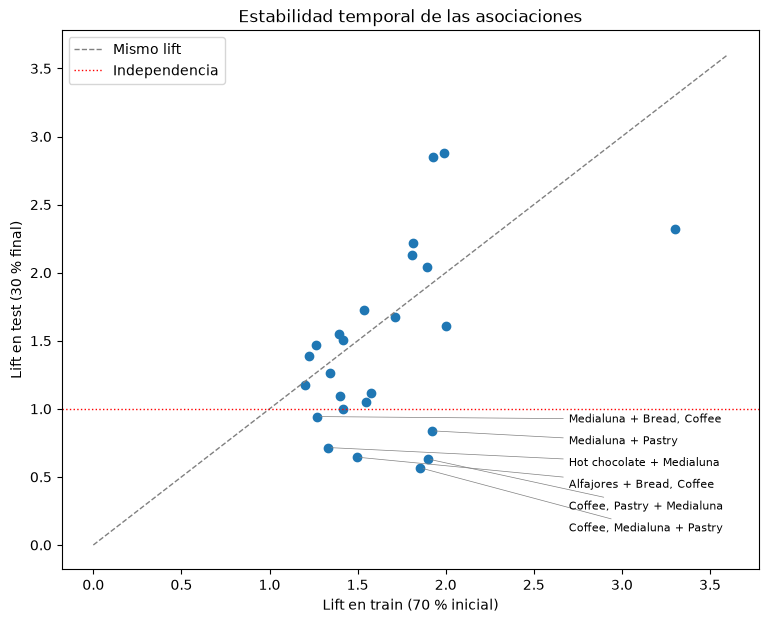

,antecedent,consequent,lift,lift_test
49,"Coffee, Medialuna",Pastry,1.86,0.57
48,"Coffee, Pastry",Medialuna,1.90,0.63
35,Alfajores,"Bread, Coffee",1.50,0.65
18,Hot chocolate,Medialuna,1.33,0.72
23,Medialuna,Pastry,1.92,0.84
37,Medialuna,"Bread, Coffee",1.27,0.94
16,Cookies,Tea,1.41,1.00
32,Toast,Tea,1.55,1.05
2,Cookies,Cake,1.40,1.09
27,Sandwich,Tea,1.57,1.12


In [36]:
basket_datetime = pd.to_datetime(transaction['date_time'], format='%d-%m-%Y %H:%M')
cutoff = basket_datetime.quantile(0.7)
is_train = (basket_datetime <= cutoff).to_numpy()
train, test = df[is_train], df[~is_train]


def stable_associations(matrix):
    found = algorithms[best_algorithm](matrix, min_support=ANALYSIS_SUPPORT, use_colnames=True)
    found_rules = association_rules(found, num_itemsets=len(matrix), metric='lift', min_threshold=USEFUL_LIFT)
    found_rules['antecedent'] = found_rules['antecedents'].apply(join_items)
    found_rules['consequent'] = found_rules['consequents'].apply(join_items)
    return collapse_directions(found_rules)


train_pairs = stable_associations(train)
train_pairs['lift_test'] = [pair_lift(test, a, c) for a, c in zip(train_pairs['antecedents'], train_pairs['consequents'])]

print(f'Train: {basket_datetime.min():%d-%m-%Y} -> {cutoff:%d-%m-%Y} ({len(train)} baskets)')
print(f'Test:  {cutoff:%d-%m-%Y} -> {basket_datetime.max():%d-%m-%Y} ({len(test)} baskets)')
print(f'Associations found in train (lift >= {USEFUL_LIFT}): {len(train_pairs)}')
print(f"  still positive in test (lift > 1): {(train_pairs['lift_test'] > 1).sum()}")
print(f"  still useful in test (lift >= {USEFUL_LIFT}): {(train_pairs['lift_test'] >= USEFUL_LIFT).sum()}")
print(f"  not computable in test (item not sold): {train_pairs['lift_test'].isna().sum()}")

plt.figure(figsize=(9, 7))
plt.scatter(train_pairs['lift'], train_pairs['lift_test'])
unstable = train_pairs[train_pairs['lift_test'] < 1].sort_values('lift_test').reset_index(drop=True)
label_x = train_pairs['lift'].max() - 0.6
for i, row in unstable.iterrows():
    plt.annotate(f"{row['antecedent']} + {row['consequent']}", (row['lift'], row['lift_test']),
                 xytext=(label_x, 0.1 + 0.16 * i), fontsize=8,
                 arrowprops={'arrowstyle': '-', 'color': 'gray', 'linewidth': 0.5})
limits = [0, max(train_pairs['lift'].max(), train_pairs['lift_test'].max()) + 0.3]
plt.plot(limits, limits, linestyle='--', color='gray', linewidth=1, label='Mismo lift')
plt.axhline(1, linestyle=':', color='red', linewidth=1, label='Independencia')
plt.xlabel('Lift en train (70 % inicial)')
plt.ylabel('Lift en test (30 % final)')
plt.title('Estabilidad temporal de las asociaciones')
plt.legend()
plt.show()

train_pairs[['antecedent', 'consequent', 'lift', 'lift_test']].sort_values('lift_test').round(2)

In [37]:
not_found_in_train = collapse_directions(positive)
not_found_in_train = not_found_in_train[~not_found_in_train['pair'].isin(set(train_pairs['pair']))].copy()
not_found_in_train['n_train'] = [int((basket_mask(train, a) & basket_mask(train, c)).sum())
                                 for a, c in zip(not_found_in_train['antecedents'], not_found_in_train['consequents'])]
not_found_in_train['lift_train'] = [pair_lift(train, a, c) for a, c in zip(not_found_in_train['antecedents'], not_found_in_train['consequents'])]
not_found_in_train['lift_test'] = [pair_lift(test, a, c) for a, c in zip(not_found_in_train['antecedents'], not_found_in_train['consequents'])]
print(f'Minimum baskets required in train: {ANALYSIS_SUPPORT * len(train):.0f}')
not_found_in_train[['antecedent', 'consequent', 'n_train', 'lift_train', 'lift_test']].round(2)

Minimum baskets required in train: 33


,antecedent,consequent,n_train,lift_train,lift_test
100,Coke,Sandwich,27,3.90,3.22
125,Soup,Sandwich,29,2.24,2.07
112,Juice,Sandwich,29,2.12,1.91
49,Juice,Cake,32,1.65,1.72
188,"Coffee, Tea",Sandwich,33,1.57,1.39
83,Salad,Coffee,20,1.43,1.21
178,"Cake, Hot chocolate",Coffee,38,1.16,1.41
91,Spanish Brunch,Coffee,28,1.17,1.23


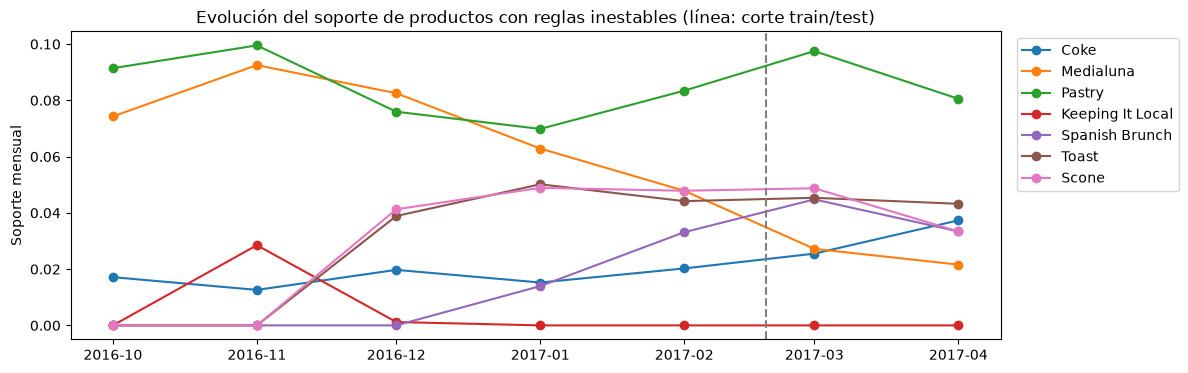

In [38]:
TRACKED_ITEMS = ['Coke', 'Medialuna', 'Pastry', 'Keeping It Local', 'Spanish Brunch', 'Toast', 'Scone']
basket_month = basket_datetime.dt.to_period('M').dt.to_timestamp().to_numpy()
monthly_support = df[TRACKED_ITEMS].groupby(basket_month).mean()

plt.figure(figsize=(12, 4))
for item in TRACKED_ITEMS:
    plt.plot(monthly_support.index, monthly_support[item], marker='o', label=item)
plt.axvline(cutoff, linestyle='--', color='gray')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.ylabel('Soporte mensual')
plt.title('Evolución del soporte de productos con reglas inestables (línea: corte train/test)')
plt.show()

- **Núcleo estable.** De las 26 asociaciones encontradas en train, **19 siguen siendo positivas en test y 14 mantienen lift ≥ 1.2**. Las más robustas son las de bebida + dulce: Coffee + Hot chocolate → Cake (1.99 → 2.88), Hot chocolate + Cake (1.81 → 2.22), Juice + Cookies (3.30 → 2.32), Scone + Tea (1.71 → 1.68) y Toast → Coffee (1.39 → 1.55).
- **Reglas que desaparecen: todas las de Medialuna** (Medialuna + Pastry pasa de 1.92 a 0.84). El soporte mensual de Medialuna cae del 9 % en noviembre al 2 % en abril: un cambio en la oferta o en la demanda del producto invalida sus reglas.
- **Productos con vida limitada.** Keeping It Local solo se vendió entre el 7 de noviembre y el 2 de diciembre de 2016 (posiblemente una promoción), y Spanish Brunch, Toast y Scone aparecen a partir de diciembre–enero. Ale y Rossi (2000) señalan que, para estos productos, calcular el soporte sobre todo el periodo los penaliza, y proponen medirlo solo dentro de su «vida» (soporte temporal).
- **Reglas estables que el umbral de soporte oculta.** Coke + Sandwich no se detecta en train, pero no porque no exista: tiene un lift de 3.90 en train y 3.22 en test. Solo aparece en 27 cestas de train y el umbral exige 33. Lo mismo pasa con Soup + Sandwich y Juice + Sandwich. Es de nuevo el problema de los productos poco frecuentes (Liu, Hsu y Ma, 1999): un único umbral de soporte deja fuera asociaciones fuertes y estables de productos minoritarios.

*Implicación:* las reglas tienen fecha de caducidad. Conviene recalcularlas periódicamente y distinguir el núcleo estable (bebida + dulce, menú de mediodía, café con tostada) de las reglas ligadas a productos de temporada o en declive.

#### 4.7 Implicaciones de negocio
- **Menú de mediodía.** Sandwich + Coke/Juice/Soup es la asociación más fuerte y se mantiene en el tiempo. Coke y Juice + Sandwich mantienen el lift dentro de la tarde, así que son complementariedad real. Soup + Sandwich se explica en parte por la hora, pero sigue por encima de la independencia (1.42). Es candidato natural a un combo con precio conjunto (*price bundling*; Stremersch y Tellis, 2002). Al ser complementariedad, el precio sí puede influir en la demanda conjunta (Manchanda et al., 1999).
- **Venta cruzada en el mostrador.** Sugerir en la dirección con más confianza, desde el producto menos frecuente: Toast → Coffee, Hot chocolate → Cake, Scone → Tea, Juice → Cookies.
- **Surtido.** Productos con ventas propias modestas, como Cookies, Juice o Scone, generan asociaciones fuertes y estables. Brijs et al. (2004) muestran que este potencial de venta cruzada debe tenerse en cuenta al decidir el surtido (modelo PROFSET), no solo las ventas individuales. Medialuna, en cambio, pierde peso y deja de generar reglas.
- **Distribución del local y promociones.** El pan para llevar y el consumo en cafetería son clientes distintos: tiene sentido separar sus flujos y no promocionarlos juntos. Tampoco conviene combinar productos sustitutos (Coffee + Tea, Pastry + Cake).
- **Contexto.** Las recomendaciones deberían depender de la franja horaria: desayuno (café + tostada o bollería) por la mañana, menú y té por la tarde.

#### 4.8 Síntesis
1. **Modelo:** Apriori, por ser el más rápido con el umbral de trabajo. Al ser exactos, los tres algoritmos llevan al mismo análisis.
2. **28 asociaciones positivas significativas**, organizadas en tres misiones de compra: bebida + dulce, comida de mediodía y desayuno con café.
3. **La confianza sola engaña.** Coffee aparece como consecuente con confianza alta por ser muy frecuente, no por estar asociado. Lift, conviction y el par Kulczynski–Imbalance Ratio dan una lectura más fiable, y la dirección de la regla debe partir del producto menos frecuente.
4. **No todo lift alto es complementariedad.** Parte de la asociación Soup + Sandwich se debe a la hora de compra; Coke + Sandwich y las combinaciones bebida + dulce sí son complementariedad real.
5. **Las asociaciones negativas** revelan dos tipos de cliente (pan para llevar frente a consumo en cafetería) y productos sustitutos (Coffee/Tea, Pastry/Cake).
6. **Validación:** la mayoría de las reglas resisten la corrección por comparaciones múltiples y se repiten en el periodo final. Las que fallan están ligadas a productos en declive o de temporada (Medialuna, Keeping It Local).

#### Referencias
- Ale, J. M., y Rossi, G. H. (2000). An approach to discovering temporal association rules. *Proc. ACM Symposium on Applied Computing (SAC)*.
- Benjamini, Y., y Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society B*, 57(1), 289–300.
- Brijs, T., Swinnen, G., Vanhoof, K., y Wets, G. (2004). Building an association rules framework to improve product assortment decisions. *Data Mining and Knowledge Discovery*, 8(1), 7–23.
- Brin, S., Motwani, R., y Silverstein, C. (1997). Beyond market baskets: Generalizing association rules to correlations. *Proc. ACM SIGMOD*.
- Brin, S., Motwani, R., Ullman, J. D., y Tsur, S. (1997). Dynamic itemset counting and implication rules for market basket data. *Proc. ACM SIGMOD*, 255–264.
- Fabris, C. C., y Freitas, A. A. (2000). Discovering surprising patterns by detecting occurrences of Simpson's paradox. *Research and Development in Intelligent Systems XVI*, 148–160.
- Liu, B., Hsu, W., y Ma, Y. (1999). Mining association rules with multiple minimum supports. *Proc. ACM SIGKDD*.
- Manchanda, P., Ansari, A., y Gupta, S. (1999). The "shopping basket": A model for multicategory purchase incidence decisions. *Marketing Science*, 18(2), 95–114.
- Russell, G. J., y Petersen, A. (2000). Analysis of cross category dependence in market basket selection. *Journal of Retailing*, 76(3), 367–392.
- Sarantopoulos, P., Theotokis, A., Pramatari, K., y Doukidis, G. (2016). Shopping missions: An analytical method for the identification of shopper need states. *Journal of Business Research*, 69(3), 1043–1052.
- Savasere, A., Omiecinski, E., y Navathe, S. (1998). Mining for strong negative associations in a large database of customer transactions. *Proc. IEEE ICDE*, 494–502.
- Stremersch, S., y Tellis, G. J. (2002). Strategic bundling of products and prices: A new synthesis for marketing. *Journal of Marketing*, 66(1), 55–72.
- Tan, P.-N., Kumar, V., y Srivastava, J. (2004). Selecting the right objective measure for association analysis. *Information Systems*, 29(4), 293–313.
- Webb, G. I. (2007). Discovering significant patterns. *Machine Learning*, 68(1), 1–33.
- Wu, T., Chen, Y., y Han, J. (2010). Re-examination of interestingness measures in pattern mining: A unified framework. *Data Mining and Knowledge Discovery*, 21(3), 371–397.
- Wu, X., Zhang, C., y Zhang, S. (2004). Efficient mining of both positive and negative association rules. *ACM Transactions on Information Systems*, 22(3), 381–405.